#### Kaggle: https://www.kaggle.com/c/sai-vessel-segmentation2

IMG_SIZE = 512

In [1]:
# 本專案用 uv 管理環境，且 venv 內沒有 pip；安裝套件請用 uv pip
!uv pip install -q albumentations

import os
import numpy as np
import cv2
from PIL import Image
import matplotlib.pyplot as plt
from glob import glob
from tqdm.auto import tqdm
import albumentations as A
from sklearn.model_selection import train_test_split
import pandas as pd

import torch
from torch import nn
import torchvision

# Apple Silicon：有 MPS、沒有 CUDA。優先 cuda -> mps -> cpu
device = (
    'cuda' if torch.cuda.is_available()
    else 'mps' if torch.backends.mps.is_available()
    else 'cpu'
)
print(device)

torch.__version__

mps


'2.10.0'

#### Download data

In [2]:
# ✅ 資料已下載並放在 ../data/drive-vessel-seg/（train/、test/），不需重新下載。
# 如需重新取得原始壓縮檔，解除下列註解：
# !uv pip install -q --upgrade gdown
# import gdown
# gdown.download(id="1JILW10sr40CRTLiuA1mf__5GBtMDF9xc", output="vessel_seg.zip")
print("Using local dataset at ../data/drive-vessel-seg")

Using local dataset at ../data/drive-vessel-seg


In [3]:
# ✅ 資料已解壓於 ../data/drive-vessel-seg/，略過（原本：!unzip -q vessel_seg.zip）
import os
for split in ["train", "test"]:
    n = len(os.listdir(f"../data/drive-vessel-seg/{split}"))
    print(f"{split}: {n} files")

train: 40 files
test: 20 files


#### Data Analysis


---

all


*   train/
    *   id1_training.tif
    *   id1**_manual1**.gif
    *   id2_training.tif
    *   id2**_manual1**.gif
    *   ...
*   test/
    *   ...



In [4]:
# read img and mask
img_paths = sorted(glob('../data/drive-vessel-seg/train/*.tif'))
img_path = img_paths[0]
mask_path = img_path.replace('_training.tif', '_manual1.gif')

print('img path: ', img_path)
print('mask path:',  mask_path)

img = cv2.imread(img_path)[:, :, ::-1]
mask = Image.open(mask_path)
mask = np.array(mask)

img path:  ../data/drive-vessel-seg/train/21_training.tif
mask path: ../data/drive-vessel-seg/train/21_manual1.gif


Image shape: (H, W, C)

*   C: 3 RGB channels

Mask  shape: (H, W)
* 0: background
* 255: vessel

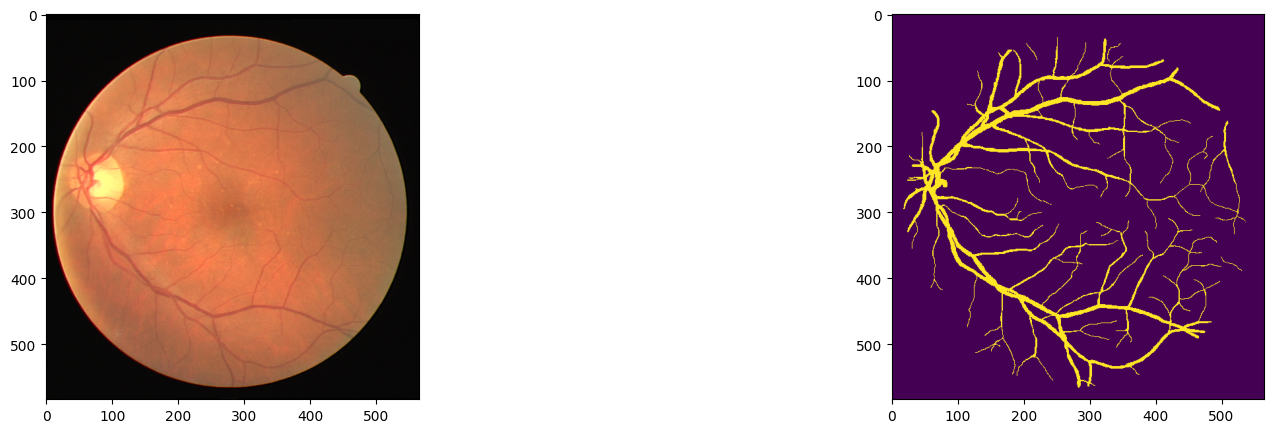

In [5]:
# show image
plt.figure(figsize=(20, 5))
plt.subplot(1,2,1)
plt.imshow(img)
plt.subplot(1,2,2)
plt.imshow(mask)
plt.show()

In [6]:
img.shape, mask.shape

((584, 565, 3), (584, 565))

In [7]:
# Calculate tumor pixel
values, counts = np.unique(mask, return_counts=True)
values, counts

(array([  0, 255], dtype=uint8), array([305302,  24658]))

# Dataset & Dataloader


In [8]:
IMG_SIZE = 512 # 32X 16X
BS = 4

In [9]:
import os
from glob import glob

import cv2
import numpy as np
from PIL import Image
from torch.utils.data import Dataset

import albumentations as A
from albumentations.pytorch import ToTensorV2


class VesselDataset(Dataset):
    def __init__(self, img_paths, img_size, mode, augmentation=False):
        """
        img_paths: list of image file paths, e.g. [..., '/path/xx_training.tif', ...]
        img_size: int, resize target (H = W = img_size)
        mode: 'train' / 'val' / 'test'
        augmentation: bool, whether to apply random augmentation
        """
        self.img_paths = img_paths
        # 對應到 mask：training.tif -> manual1.gif
        self.mask_paths = [
            m_path.replace('training.tif', 'manual1.gif')
            for m_path in self.img_paths
        ]
        self.img_size = img_size
        self.mode = mode
        self.augmentation = augmentation

        # Albumentations transforms
        base_transforms = [
            A.Resize(img_size, img_size),
            A.Normalize(
                mean=(0.485, 0.456, 0.406),
                std=(0.229, 0.224, 0.225)
            ),
            ToTensorV2()
        ]

        if augmentation:
            aug_transforms = [
                A.HorizontalFlip(p=0.5),
                A.Affine(
                    rotate=(-45, 45),
                    shear=(-16, 16),
                    scale=(0.8, 1.2),
                    fit_output=True
                ),
            ]
            transforms = aug_transforms + base_transforms
        else:
            transforms = base_transforms

        self.transform = A.Compose(transforms)

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        img_path = self.img_paths[idx]
        img = cv2.imread(img_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # test 模式：只回傳影像（沒有 mask）
        if self.mode == 'test':
            # 只對 image 做 transform
            transformed = self.transform(image=img)
            img_tensor = transformed["image"]  # (3, H, W), float32
            return img_tensor

        # 非 test：讀 mask + augmentation
        mask_path = self.mask_paths[idx]
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        # 原本邏輯：mask < 1 -> 0, 其他 -> 1
        mask = np.where(mask < 127, 0, 1).astype(np.uint8)

        # Albumentations 同步處理 image & mask
        transformed = self.transform(image=img, mask=mask)
        img_tensor = transformed["image"]          # (3, H, W), float32
        mask_tensor = transformed["mask"].long()   # (H, W), long

        return img_tensor, mask_tensor

In [10]:
all_paths = sorted(glob('../data/drive-vessel-seg/train/*.tif'))
test_paths = sorted(glob('../data/drive-vessel-seg/test/*.tif'))
train_paths, val_paths = train_test_split(all_paths, test_size=0.2)

In [11]:
train_ds = VesselDataset(train_paths, IMG_SIZE, 'train', augmentation=True)
val_ds = VesselDataset(val_paths, IMG_SIZE, 'val')
test_ds = VesselDataset(test_paths, IMG_SIZE, 'test')

train_loader = torch.utils.data.DataLoader(train_ds, BS, shuffle=True)
val_loader = torch.utils.data.DataLoader(val_ds, BS)
test_loader = torch.utils.data.DataLoader(test_ds, BS)

Visulize data

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.4285712].


img.shape:  torch.Size([3, 512, 512]) 
mask.shape:  torch.Size([512, 512])


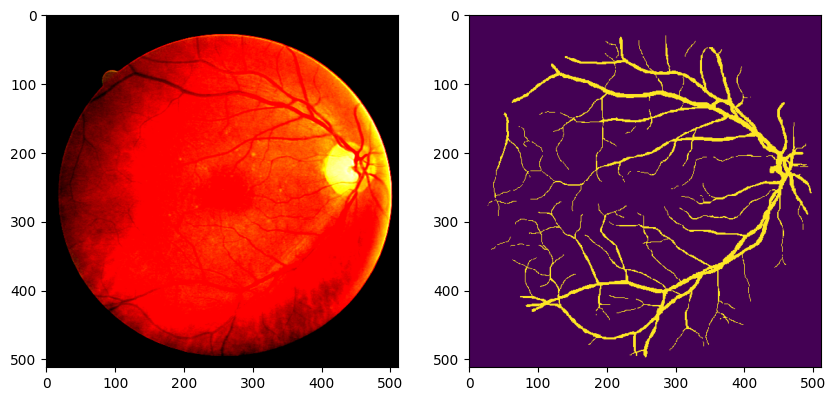

In [12]:
img, mask = train_ds[0] # take 1 data
print('img.shape: ', img.shape, '\nmask.shape: ', mask.shape)
img = img.numpy().transpose(1, 2, 0) # (C, H, W) -> (H, W, C)
mask = mask.numpy().squeeze() # (1, H, W) -> (H, W)
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.subplot(1, 2, 2)
plt.imshow(mask)
plt.show()

#### Build Model

In [13]:
import segmentation_models_pytorch as smp

In [14]:
# cuda -> mps -> cpu（同 cell 1）
device = (
    'cuda' if torch.cuda.is_available()
    else 'mps' if torch.backends.mps.is_available()
    else 'cpu'
)
print(device)

# build model and move to device
model = smp.Unet(
    encoder_name="resnet34",        # choose encoder, e.g. mobilenet_v2 or efficientnet-b7
    encoder_weights="imagenet",     # use `imagenet` pre-trained weights for encoder initialization
    in_channels=3,                  # model input channels (1 for gray-scale images, 3 for RGB, etc.)
    classes=2,                      # 二元分割用 2 個 channel：配合 multiclass Dice loss + argmax 推論
)
model = model.to(device)

mps


#### Training

In [15]:
# PyTorch Dice loss
# ⚠️ fusionlab 較舊；若與 numpy 2.x / torch 2.x 相容有問題，可改用 smp 內建損失或自寫 Dice。
!uv pip install -q fusionlab

import fusionlab as fl
from fusionlab.losses import DiceLoss, IoULoss
from fusionlab.metrics import DiceScore, IoUScore

dice_score = DiceScore(reduction="mean")

PyTorch installed: True
TensorFlow installed: False


In [16]:
def train(dataloader, model, loss_fn, optimizer):
    size = len(dataloader.dataset) # number of samples
    num_batches = len(dataloader) # batches per epoch
    model.train() # to training mode.
    epoch_loss = 0
    epoch_dice = 0
    for batch_i, (x, y) in enumerate(tqdm(dataloader, leave=False)):
        x, y = x.to(device), y.to(device) # move data to GPU
        optimizer.zero_grad()
        pred = model(x)
        loss = loss_fn(pred, y)
        loss.backward() # backpropagation to compute gradients
        optimizer.step() # update model params

        epoch_loss += loss.item() # tensor -> python value
        epoch_dice += dice_score(pred, y).item()

    # return avg loss of epoch, dice of epoch
    return epoch_loss/num_batches, epoch_dice/num_batches


def test(dataloader, model, loss_fn):
    size = len(dataloader.dataset) # number of samples
    num_batches = len(dataloader) # batches per epoch

    model.eval() # model to test mode.
    epoch_loss = 0
    epoch_dice = 0
    # No gradient for test data
    with torch.no_grad():
        for batch_i, (x, y) in enumerate(dataloader):
            x, y = x.to(device), y.to(device)

            # Compute prediction loss
            pred = model(x)
            loss = loss_fn(pred, y)

            # write to logs
            epoch_loss += loss.item()
            epoch_dice += dice_score(pred, y).item()

    return epoch_loss/num_batches, epoch_dice/num_batches

In [17]:
EPOCHS = 50
logs = {
    'train_loss': [], 'val_loss': [],
    'train_dice': [], 'val_dice': [],
}
# loss_fn = nn.CrossEntropyLoss() # classification for each pixel
loss_fn = fl.losses.DiceLoss("multiclass") # IoULoss

optimizer = torch.optim.Adam(model.parameters())
best_loss = np.inf

for epoch in tqdm(range(EPOCHS)):
    train_loss, train_dice = train(train_loader, model, loss_fn, optimizer)
    val_loss, val_dice = test(val_loader, model, loss_fn)
    logs['train_loss'].append(train_loss)
    logs['val_loss'].append(val_loss)
    logs['train_dice'].append(train_dice)
    logs['val_dice'].append(val_dice)

    print(f'EPOCH: {epoch:04d} train_loss: {train_loss:.4f} val_loss: {val_loss:.4f}, train_dice: {train_dice:.3f}, val_dice: {val_dice:.3f}')

    # On epoch end
    torch.save(model.state_dict(), "last.pth")
    # check improvement
    if val_loss < best_loss:
        best_loss = val_loss
        torch.save(model.state_dict(), "best.pth")

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/4 [00:00<?, ?it/s]

EPOCH: 0000 train_loss: 0.6024 val_loss: 0.9209, train_dice: 0.398, val_dice: 0.079


  0%|          | 0/4 [00:00<?, ?it/s]

EPOCH: 0001 train_loss: 0.5114 val_loss: 0.8298, train_dice: 0.489, val_dice: 0.170


...

EPOCH: 0047 train_loss: 0.1199 val_loss: 0.1273, train_dice: 0.880, val_dice: 0.873


  0%|          | 0/4 [00:00<?, ?it/s]

EPOCH: 0048 train_loss: 0.1250 val_loss: 0.1204, train_dice: 0.875, val_dice: 0.880


  0%|          | 0/4 [00:00<?, ?it/s]

EPOCH: 0049 train_loss: 0.1210 val_loss: 0.1456, train_dice: 0.879, val_dice: 0.854


Kaggle submission

In [18]:
model.load_state_dict(torch.load("best.pth"))

<All keys matched successfully>

In [19]:
# make prediction
# RLE: run length encoding
outputs = []
with torch.no_grad():
    for imgs in test_loader:
        imgs = imgs.to(device)
        y_preds = model(imgs).cpu().numpy()
        y_preds = np.argmax(y_preds, axis=1)
        y_preds = np.expand_dims(y_preds, axis=-1)

        for y_pred in y_preds:
            dots = np.where(y_pred.flatten() == 1)[0]
            run_lengths = []
            prev = -2
            for b in dots:
                if (b > prev +1):
                    run_lengths.extend((b+1,0))
                run_lengths[-1] += 1
                prev = b
            output = ' '.join([str(r) for r in run_lengths])
            outputs.append(output)


In [20]:
# Create submission file
df = pd.DataFrame(columns=['Id', 'Predicted'])
df['Id'] = [str(i) for i in range(20)]
df['Predicted'] = outputs
df.to_csv('submission.csv', index=None)
df

,Id,Predicted
0,0,15621 3 16133 4 16616 3 16646 3 16676 2 17128 ...
1,1,16641 5 16659 2 17154 6 17170 4 17668 5 17682 ...
2,2,13580 6 14091 7 14544 2 14601 7 15055 3 15112 ...
3,3,14584 4 15096 5 15609 4 16122 4 16634 5 16689 ...
4,4,17188 2 17663 5 17700 2 18174 6 18210 5 18684 ...
5,5,17664 1 18118 2 18629 3 18727 4 19141 3 19240 ...
6,6,16144 1 16655 3 17128 3 17138 1 17167 4 17637 ...
7,7,16105 2 16617 4 16657 5 17129 5 17169 5 17642 ...
8,8,16115 2 16148 4 16627 3 16659 6 17140 3 17170 ...
9,9,16640 3 17114 2 17152 3 17625 4 17664 4 18137 ...


#### Other Image Augmentation modules

In [ ]:
# ⚠️ 這是「另一種 augmentation 寫法」的示範（imgaug），不是本 notebook 主線。
# imgaug 已停止維護、且不相容於本環境的 numpy 2.x；原本的
#     !pip install numpy==1.26.3
# 會把整個 venv 的 numpy 降版而弄壞 torch，已移除。
# 主線請用 cell 13 的 albumentations 版 VesselDataset。
# 若真的要試 imgaug，請「另建」一個 numpy<2 的獨立環境後再解除下列註解：
# !uv pip install -q "numpy<2" imgaug
# import imgaug

# imgaug (legacy reference implementation)
class VesselDataset(torch.utils.data.Dataset):
    def __init__(self, img_paths, img_size, mode, augmentation=False):
        """
        mode: str, 'train' 'val' 'test'
        """
        self.img_paths = img_paths
        self.mask_paths = [m_path.replace('training.tif', 'manual1.gif') for m_path in self.img_paths]
        self.img_size = img_size
        self.mode = mode
        # Augmentation
        self.augmentation = augmentation
        self.augmentor = imgaug.augmenters.Sequential([
            imgaug.augmenters.Fliplr(0.5), # 50% horizontal flip
            imgaug.augmenters.Affine(
                rotate=(-45, 45), # random rotate -45 ~ +45 degree
                shear=(-16,16), # random shear -16 ~ +16 degree
                scale={"x": (0.8, 1.2), "y": (0.8, 1.2)} # scale x, y: 80%~120%
            ),
        ])
    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        img_path = self.img_paths[idx]
        img = cv2.imread(img_path)[:, :, ::-1]
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE)) # (IMG_SIZE, IMG_SIZE, 3)
        # Normalize Image
        img = img / 255. # 0~255 -> 0~1

        if self.mode != 'test':
            mask_path = self.mask_paths[idx]
            mask = np.array(Image.open(mask_path))
            mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE)) # (IMG_SIZE, IMG_SIZE)
            # Binarize mask from [0~255] to (0 or 1)
            # mask = np.where(mask<1, 0, 1).astype(np.int16)
            mask = np.where(mask<127, 0, 1).astype(np.int16)

            # Augment mask by imgaug
            if self.augmentation:
                # to imgaug data class
                mask = imgaug.augmentables.segmaps.SegmentationMapsOnImage(mask,
                                                                    shape=mask.shape)
                # augment img & mask "simultaneously"
                img, mask = self.augmentor(image=img, segmentation_maps=mask)
                mask = mask.get_arr() # to np.ndarray

            # 1. Convert to PyTorch Tensor
            # 2. Channel last to first: (H, W, C) -> (C, H, W)
            # Tensor datatype:
            # Img: float, Mask: long
            img = torch.tensor(img, dtype=torch.float).permute(2, 0, 1)
            mask = torch.tensor(mask, dtype=torch.long)
            return img, mask
        else:
            img_tensor = torch.tensor(img, dtype=torch.float).permute(2, 0, 1)
            return img_tensor

#### Other modules

In [ ]:
!uv pip install -q segmentation-models-pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 12.2 MB/s eta 0:00:00


In [ ]:
import segmentation_models_pytorch as smp

model = smp.Unet(
    encoder_name="resnet34",        # choose encoder, e.g. mobilenet_v2 or efficientnet-b7
    encoder_weights="imagenet",     # use `imagenet` pre-trained weights for encoder initialization
    in_channels=3,                  # model input channels (1 for gray-scale images, 3 for RGB, etc.)
    classes=2,                      # model output channels (number of classes in your dataset)
)
model = model.to(device)

In [ ]:
!uv pip install -q fusionlab
import fusionlab as fl

In [ ]:
model = fl.segmentation.ResUNet(cin=3,
                                num_cls=2,
                                base_dim=32,
                                spatial_dims=2)
model = model.to(device)

In [ ]:
import torch

inputs = torch.randn(1, 3, 256, 256)
outputs = model(inputs)

outputs.shape

torch.Size([1, 2, 256, 256])